<a href="https://www.kaggle.com/code/mukeshkumar95/ecommerce-clothing-classifier-model-with-keras?scriptVersionId=366103618" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mukeshkumar95/fashion-mnist/fashion_mnist.npz
/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_test.csv
/kaggle/input/datasets/zalando-research/fashionmnist/fashion-mnist_train.csv
/kaggle/input/datasets/zalando-research/fashionmnist/t10k-images-idx3-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/t10k-labels-idx1-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/train-images-idx3-ubyte
/kaggle/input/datasets/zalando-research/fashionmnist/train-labels-idx1-ubyte


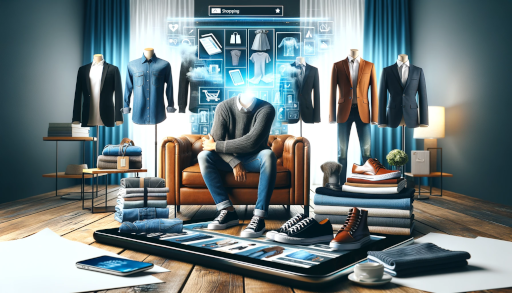

_Fashion Forward_ is a new AI-based e-commerce clothing retailer. They want to use image classification to automatically categorize new product listings, making it easier for customers to find what they're looking for. It will also assist in inventory management by quickly sorting items.

As a data scientist tasked with implementing a clothing classifier, my primary objective is to develop a deep learning model capable of accurately categorizing images of clothing items into distinct garment types such as shirts, trousers, shoes, etc.

In [2]:
# Run the cells below first
from tensorflow.keras import layers, models, Sequential
from keras.layers import Dense, Conv2D, Flatten
from tensorflow.keras.utils import to_categorical
import numpy as np

# Load the MNIST datasets as NumPy arrays
train_images, train_labels, test_images, test_labels = (np.load('/kaggle/input/datasets/mukeshkumar95/fashion-mnist/fashion_mnist.npz')[key] 
                                    for key in ['train_images', 'train_labels', 'test_images', 'test_labels'])

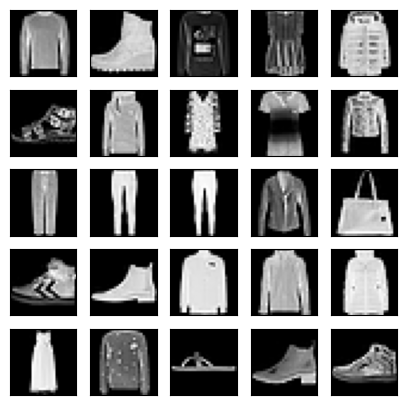

In [3]:
# Visualize a sample of images
import matplotlib.pyplot as plt
plt.figure(figsize=(5,5))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i]/255.0, cmap='gray')
plt.show()

In [4]:
num_classes=len(set(train_labels))

In [5]:
print(num_classes)

10


In [6]:
img_size=train_images[0].shape[0]

In [7]:
print(img_size)

28


In [8]:
#convert the labels to 1 hot encoded form
train_labels_1h=to_categorical(train_labels)
test_labels_1h=to_categorical(test_labels)

In [9]:
#define the model
model=Sequential()

In [10]:
#adding a convolution layer with 32 filters of size 3x3
model.add(Conv2D(32,kernel_size=3, input_shape=(img_size, img_size,1),activation='relu'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [11]:
#adding a convolutional layer with 16 filters of size 3x3
model.add(Conv2D(16, kernel_size=3,activation='relu'))

In [12]:
model.add(Flatten())#flatten teh previous layer output

In [13]:
#adding as many outputs as classes with softmax activation
model.add(Dense(num_classes, activation='softmax'))

In [14]:
#compile the model
model.compile(optimizer='adam',
             loss='categorical_crossentropy',
             metrics=['accuracy'])

In [15]:
#print the model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        92,170 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,114 (379.35 KB)

 Trainable params: 97,114 (379.35 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:

# Fit the model to the training data
model.fit(train_images, train_labels_1h,
          validation_split=0.2,
          epochs=1, batch_size=100)

240/240 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - accuracy: 0.7715 - loss: 1.6714 - val_accuracy: 0.8428 - val_loss: 0.4493


In [17]:
#evaluate the model on the test dataset
scores=model.evaluate(test_images, test_labels_1h, batch_size=100)
test_accuracy=scores[-1]
print(f'Test accruacy: {test_accuracy: .2f}')

50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8346 - loss: 0.4773
Test accruacy:  0.83
